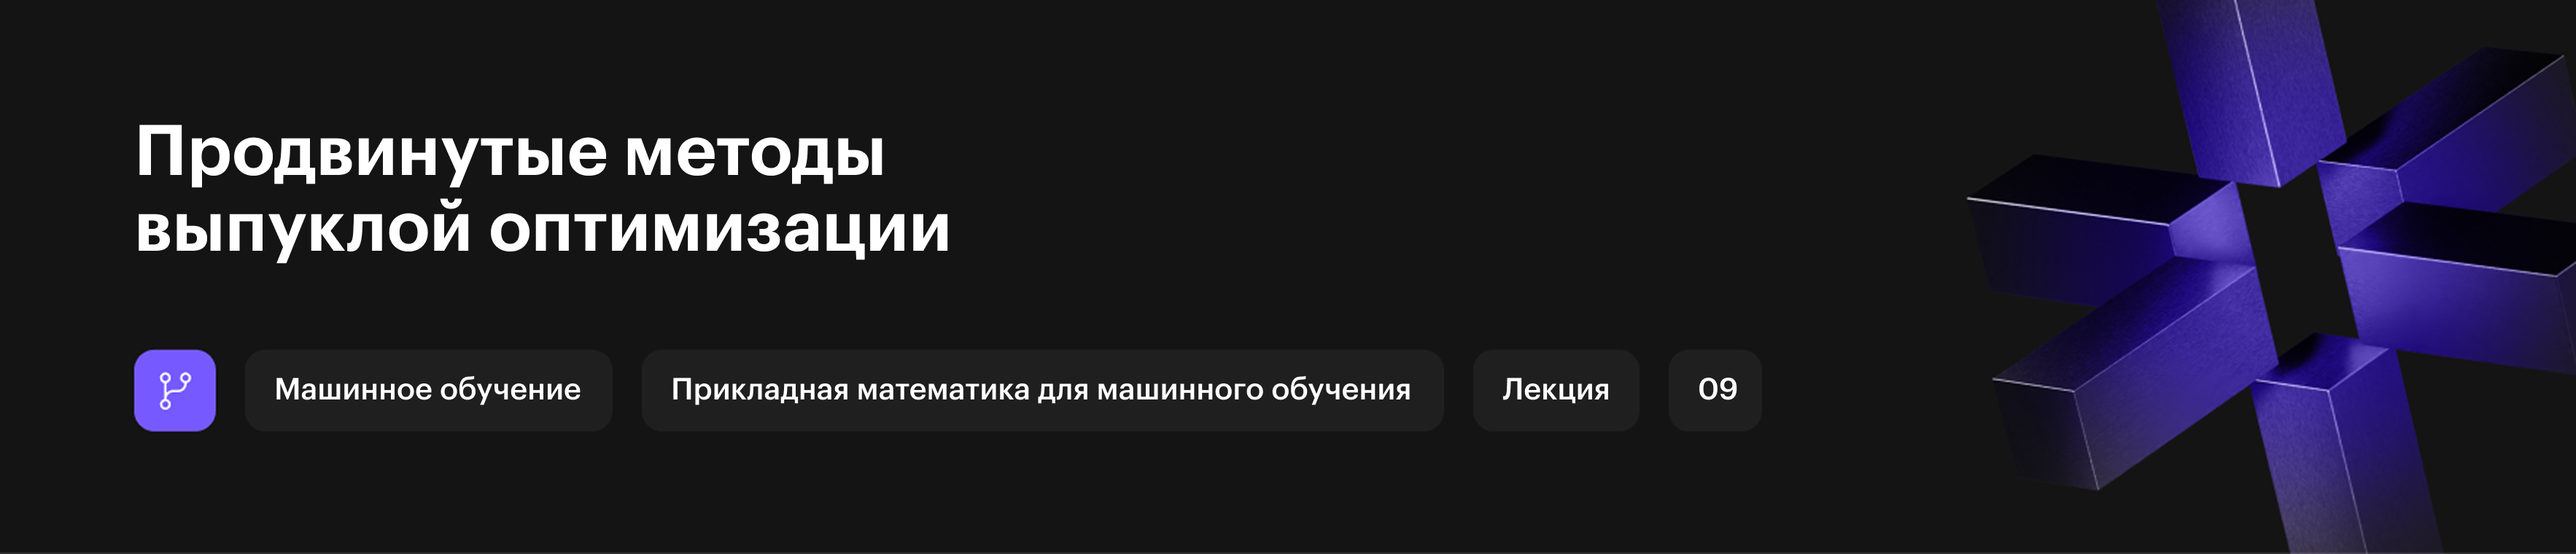

# Неделя 9. Продвинутые методы выпуклой оптимизации


Обозначения: $g_k=\nabla f(x^k)$, $G_k=\nabla^2 f(x^k)$,
$H_k$ — приближение обратного гессиана, $p_k$ — направление шага,
$x^{k\,+\,1}=x^k+\alpha_kp_k$.


In [ ]:
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import line_search


def armijo(f, x, g, p, c1=1e-4, beta=0.5, alpha0=1.0, max_trials=60):
    """Дробление для общего направления p; alpha заново начинается с alpha0."""
    slope = float(g @ p)
    if not np.isfinite(slope) or slope >= 0:
        raise ValueError("Для Армихо нужно направление спуска: g @ p < 0")
    fx = float(f(x))
    alpha = float(alpha0)
    for _ in range(max_trials):
        trial = float(f(x + alpha * p))
        if np.isfinite(trial) and trial <= fx + c1 * alpha * slope:
            return alpha
        alpha *= beta
    raise RuntimeError("Не удалось подобрать шаг по Армихо")


def bfgs_update(H, s, y, curvature_tol=1e-10):
    """Возвращает (новая матрица, принято ли обновление). Гессиан не нужен."""
    sy = float(s @ y)
    scale = float(np.linalg.norm(s) * np.linalg.norm(y))
    if not np.isfinite(sy) or sy <= curvature_tol * scale or sy <= 0:
        return H.copy(), False
    rho = 1.0 / sy
    V = np.eye(len(s)) - rho * np.outer(s, y)
    updated = V @ H @ V.T + rho * np.outer(s, s)
    return 0.5 * (updated + updated.T), True


def numerical_gradient(f, x, h=1e-5):
    x = np.asarray(x, dtype=float)
    E = np.eye(len(x))
    return np.array([(f(x+h*e)-f(x-h*e))/(2*h) for e in E])


def numerical_hessian(f, x, h=1e-4):
    """Центральные разности; диагональ считается отдельной формулой."""
    x = np.asarray(x, dtype=float)
    E = np.eye(len(x))
    G = np.zeros((len(x), len(x)))
    fx = f(x)
    for i, ei in enumerate(E):
        G[i, i] = (f(x+h*ei) - 2*fx + f(x-h*ei)) / h**2
        for j in range(i):
            ej = E[j]
            value = (f(x+h*ei+h*ej) - f(x+h*ei-h*ej)
                     - f(x-h*ei+h*ej) + f(x-h*ei-h*ej)) / (4*h**2)
            G[i, j] = G[j, i] = value
    return G


def _run(f, grad, x0, *, kind, hess=None, mode="armijo", search="wolfe",
         gamma=1.0, gtol=1e-6, f_star=None, ftol=1e-4, maxiter=1000,
         max_norm=1e12, keep_H=False):
    """Общий цикл и единая история принятых точек. Время не включает графики.

    mode для Ньютона: full, armijo, shifted. search для BFGS: wolfe,
    armijo, fixed. При f_star != None остановка по |f-f_star| < ftol;
    иначе по норме градиента. Критерий проверяется ДО нового шага.
    """
    if gamma <= 0 or gtol <= 0 or ftol <= 0 or maxiter < 0:
        raise ValueError("Проверьте gamma, точности и maxiter")
    if kind not in {"gd", "newton", "bfgs"}:
        raise ValueError("Неизвестный метод")
    if mode not in {"full", "armijo", "shifted"} or search not in {"wolfe", "armijo", "fixed"}:
        raise ValueError("Неизвестный способ выбора шага")
    x = np.asarray(x0, dtype=float).copy()
    if x.ndim != 1 or not np.all(np.isfinite(x)):
        raise ValueError("x0 должен быть конечным вектором")
    calls = {"f": 0, "grad": 0, "hess": 0}
    def F(z):
        calls["f"] += 1
        return float(f(z))
    def D(z):
        calls["grad"] += 1
        return np.asarray(grad(z), dtype=float)
    started = time.perf_counter()
    H = gamma * np.eye(len(x))
    fx, g = F(x), D(x)
    xs, fs, gs = [x.copy()], [fx], [float(np.linalg.norm(g))]
    alphas, curvatures, updates, shifts, Hs = [], [], [], [], [H.copy()] if keep_H else []
    fallbacks = 0
    status, message = "iteration_limit", "Достигнут предел итераций"
    for k in range(maxiter + 1):
        if not np.isfinite(fx) or not np.all(np.isfinite(g)):
            status, message = "nonfinite", "Неконечная функция или градиент"
            break
        converged = abs(fx - f_star) < ftol if f_star is not None else np.linalg.norm(g) <= gtol
        if converged:
            status, message = "converged", "Выполнен заданный критерий точности"
            break
        if k == maxiter:
            break
        tau = 0.0
        if kind == "gd":
            p = -g
        elif kind == "newton":
            calls["hess"] += 1
            G = np.asarray(hess(x), dtype=float)
            if G.shape != (len(x), len(x)) or not np.all(np.isfinite(G)):
                status, message = "invalid_hessian", "Некорректный гессиан"
                break
            if not np.allclose(G, G.T, rtol=1e-8, atol=1e-10):
                status, message = "invalid_hessian", "Гессиан несимметричен"
                break
            if mode == "shifted":
                tau = max(0.0, 1e-6 - float(np.linalg.eigvalsh(G).min()))
                G = G + tau * np.eye(len(x))
            if mode != "full":
                try:
                    np.linalg.cholesky(G)
                except np.linalg.LinAlgError:
                    status, message = "non_spd", "Нужна положительно определённая модель"
                    break
            try:
                p = np.linalg.solve(G, -g)
            except np.linalg.LinAlgError:
                status, message = "singular", "Гессиан вырожден; шаг не выполнен"
                break
        else:
            p = -H @ g
            if float(g @ p) >= 0:
                H = gamma * np.eye(len(x))
                p = -H @ g
                fallbacks += 1
        full = (kind == "newton" and mode == "full") or (kind == "bfgs" and search == "fixed")
        try:
            if full:
                alpha = 1.0
            elif kind == "bfgs" and search == "wolfe":
                # SciPy реализует поиск с сильными условиями Вульфа
                # Предупреждение сохраняется в журнале результата через счётчик fallback
                with warnings.catch_warnings(record=True):
                    search_result = line_search(F, D, x, p, gfk=g, old_fval=fx,
                                                c1=1e-4, c2=0.9, maxiter=30)
                    alpha = search_result[0]
                if (alpha is None or search_result[-1] is None
                        or not np.isfinite(alpha) or alpha <= 0):
                    alpha = armijo(F, x, g, p)
                    fallbacks += 1
            else:
                alpha = armijo(F, x, g, p)
        except (RuntimeError, ValueError) as error:
            status, message = "line_search_failed", str(error)
            break
        xn = x + alpha * p
        if not np.all(np.isfinite(xn)) or np.linalg.norm(xn) > max_norm:
            status, message = "diverged", "Остановлено: слишком большая или неконечная точка"
            break
        fn, gn = F(xn), D(xn)
        if not np.isfinite(fn) or not np.all(np.isfinite(gn)):
            status, message = "nonfinite_trial", "Пробная точка не принята: неконечные значения"
            break
        if kind == "bfgs":
            s, y = xn - x, gn - g
            H, accepted = bfgs_update(H, s, y)
            curvatures.append(float(s @ y))
            updates.append(accepted)
            if keep_H:
                Hs.append(H.copy())
        x, fx, g = xn, fn, gn
        xs.append(x.copy()); fs.append(fx); gs.append(float(np.linalg.norm(g)))
        alphas.append(float(alpha)); shifts.append(tau)
    return dict(x=x.copy(), fun=fx, grad_norm=float(np.linalg.norm(g)),
                nit=len(xs)-1, status=status, message=message,
                history=np.array(xs), f_history=np.array(fs), grad_history=np.array(gs),
                alphas=np.array(alphas), curvatures=np.array(curvatures),
                updates=np.array(updates, dtype=bool), shifts=np.array(shifts),
                H_history=Hs, fallbacks=fallbacks, calls=calls,
                elapsed=time.perf_counter()-started)


def gradient_descent(f, grad, x0, **kwargs):
    return _run(f, grad, x0, kind="gd", **kwargs)


def newton(f, grad, hess, x0, mode="full", **kwargs):
    return _run(f, grad, x0, kind="newton", hess=hess, mode=mode, **kwargs)


def bfgs(f, grad, x0, search="wolfe", gamma=1.0, **kwargs):
    return _run(f, grad, x0, kind="bfgs", search=search, gamma=gamma, **kwargs)


def quadratic(a=1.0):
    """f = a*x1**2+x2**2; минимум и минимальное значение равны нулю."""
    A = np.diag([2*a, 2.0])
    return (lambda x: float(x @ A @ x / 2), lambda x: A @ x,
            lambda x: A.copy())


def rosenbrock(x):
    u, v = x
    return float(100*(v-u*u)**2 + (1-u)**2)


def rosen_grad(x):
    u, v = x
    return np.array([400*u*(u*u-v)+2*(u-1), 200*(v-u*u)])


def rosen_hess(x):
    u, v = x
    return np.array([[1200*u*u-400*v+2, -400*u], [-400*u, 200.0]])


def report(results):
    print(f"{'Метод':24s} {'шаги':>6s} {'f(x)':>12s} {'||g||':>12s} {'сек.':>9s}  статус; вызовы f/g/G")
    for name, r in results.items():
        print(f"{name:24s} {r['nit']:6d} {r['fun']:12.4e} {r['grad_norm']:12.3e} "
              f"{r['elapsed']:9.4f}  {r['status']}; {r['calls']}")


def plot_results(f, results, title="", f_star=0.0):
    """Графики строятся после измерения времени методов."""
    if not results:
        print("Результатов пока нет: выполните задание выше.")
        return
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    paths = np.concatenate([r['history'] for r in results.values()])
    lo, hi = paths.min(axis=0), paths.max(axis=0)
    pad = max(float(np.max(hi-lo)), 1.0)*0.12
    lo, hi = lo-pad, hi+pad
    U, V = np.meshgrid(np.linspace(lo[0],hi[0],130), np.linspace(lo[1],hi[1],130))
    Z = np.array([f(z) for z in np.c_[U.ravel(), V.ravel()]]).reshape(U.shape)
    axes[1].contour(U,V,Z,levels=18,linewidths=0.6,alpha=0.6)
    for name, r in results.items():
        errors = np.abs(r['f_history']-f_star)
        positive = errors > 0
        axes[0].semilogy(np.flatnonzero(positive),errors[positive],'.-',label=name)
        if np.any(~positive):
            axes[0].annotate(f"{name}: ошибка = 0 на k={np.flatnonzero(~positive)[0]}",
                             xy=(0.02, 0.04+0.06*list(results).index(name)),
                             xycoords='axes fraction', fontsize=8)
        path=r['history']
        axes[1].plot(path[:,0],path[:,1],'.-',label=name)
    axes[0].set(xlabel='Принятые шаги k',ylabel='|f(x^k) - f*|',title='Ошибка по функции')
    axes[1].set(xlabel='x1',ylabel='x2',title='Принятые точки на линиях уровня')
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=8)
    fig.suptitle(title); fig.tight_layout(); plt.show()


## 1. Квадратичная модель и один полный шаг
Полный метод Ньютона на строго выпуклой квадратичной функции попадает в минимум за один шаг. Сравниваем число шагов, время и форму линий уровня.


Метод                      шаги         f(x)        ||g||      сек.  статус; вызовы f/g/G
Градиент + Армихо             1   0.0000e+00    0.000e+00    0.0001  converged; {'f': 5, 'grad': 2, 'hess': 0}
Полный Ньютон                 1   0.0000e+00    0.000e+00    0.0001  converged; {'f': 2, 'grad': 2, 'hess': 1}
BFGS + Вульф                  1   0.0000e+00    0.000e+00    0.0001  converged; {'f': 4, 'grad': 3, 'hess': 0}


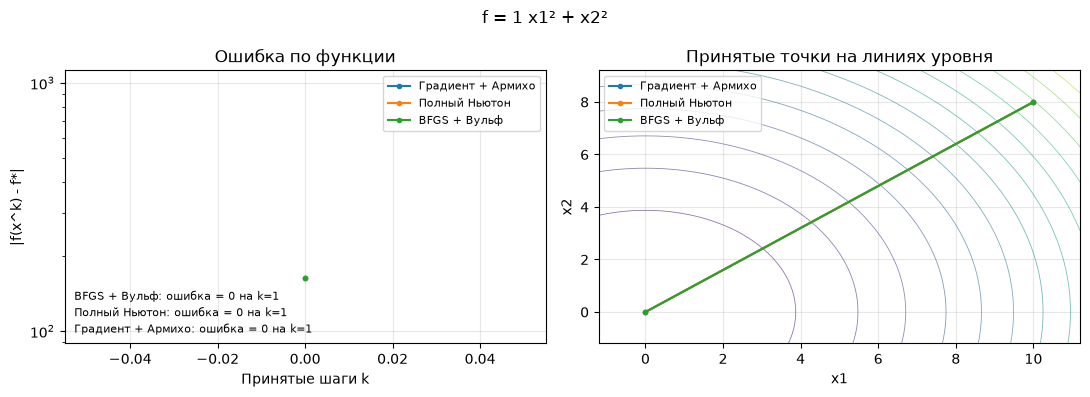

Метод                      шаги         f(x)        ||g||      сек.  статус; вызовы f/g/G
Градиент + Армихо           302   9.6253e-05    2.672e-02    0.0082  converged; {'f': 2899, 'grad': 303, 'hess': 0}
Полный Ньютон                 1   0.0000e+00    0.000e+00    0.0001  converged; {'f': 2, 'grad': 2, 'hess': 1}
BFGS + Вульф                  2   1.4781e-29    7.689e-14    0.0002  converged; {'f': 12, 'grad': 5, 'hess': 0}


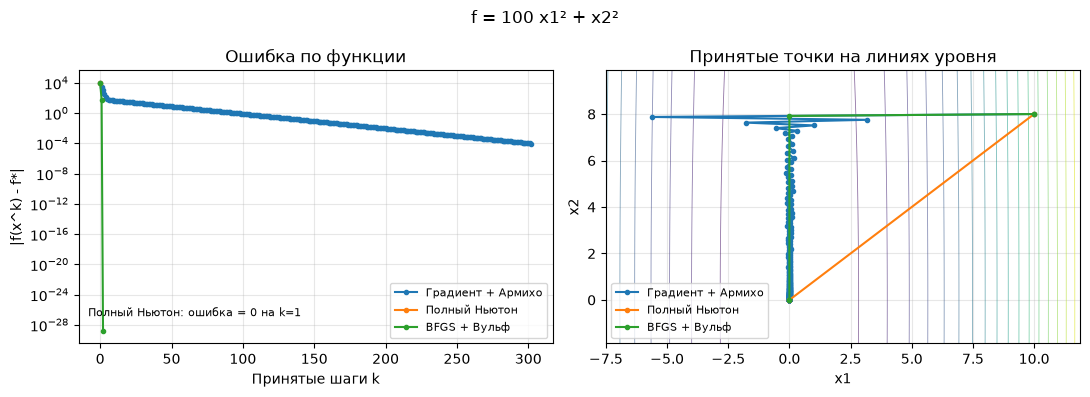

In [ ]:
for a in (1.0, 100.0):
    f, grad, hess = quadratic(a)
    x0 = np.array([10., 8.])
    results = {
        'Градиент + Армихо': gradient_descent(f, grad, x0, f_star=0.0),
        'Полный Ньютон': newton(f, grad, hess, x0, f_star=0.0),
        'BFGS + Вульф': bfgs(f, grad, x0, f_star=0.0),
    }
    report(results)
    assert results['Полный Ньютон']['nit'] == 1
    plot_results(f, results, title=f'f = {a:g} x1² + x2²')


## 2. Положительно определённая матрица Гессе не гарантирует сходимость при полном шаге
Для $\phi(t)=\sqrt{1+t^2}$ полный шаг задаётся $t_{k\,+\,1}=-t_k^3$.
Это гладкая выпуклая функция с липшицевым градиентом, но при $|t_0|>1$
полные шаги расходятся.


In [ ]:
f_rad = lambda x: float(np.hypot(1.0, x[0]))
g_rad = lambda x: np.array([x[0] / np.hypot(1.0, x[0])])
G_rad = lambda x: np.array([[np.hypot(1.0, x[0]) ** (-3)]])
for start in (0.5, 1.0, 2.0):
    full = newton(f_rad, g_rad, G_rad, [start], mode='full', maxiter=8)
    damped = newton(f_rad, g_rad, G_rad, [start], mode='armijo', maxiter=100)
    print('Старт:', start, 'полный:', full['status'], full['history'][:, 0])
    print('Армихо:', damped['status'], damped['x'], 'шаги:', damped['alphas'])


Старт: 0.5 полный: converged [ 5.0000000e-01 -1.2500000e-01  1.9531250e-03 -7.4505806e-09]
Армихо: converged [-7.4505806e-09] шаги: [1. 1. 1.]
Старт: 1.0 полный: iteration_limit [ 1. -1.  1. -1.  1. -1.  1. -1.  1.]
Армихо: converged [-2.22044605e-16] шаги: [0.5]
Старт: 2.0 полный: diverged [ 2.00000000e+00 -8.00000000e+00  5.12000000e+02 -1.34217728e+08]
Армихо: converged [7.4505806e-09] шаги: [0.25 1.   1.   1.  ]


## 3. Направление спуска, Армихо и сдвиг гессиана
Армихо: $f(x+\alpha p)\le f(x)+c_1\alpha g^Tp$.
Условие $g^Tp<0$ проверяется отдельно. Для невыпуклой задачи возможен сдвиг
$G+\tau I\succ0$; он меняет направление, а не только длину шага.
На функции Розенброка рассмотрим защищённый метод. При старте из $(0,1)$ у нас неопределённая матрица Гессе.


Спектр исходного G: [-398.  200.]
Без сдвига: non_spd Нужна положительно определённая модель
Метод                      шаги         f(x)        ||g||      сек.  статус; вызовы f/g/G
Ньютон со сдвигом             9   3.1229e-19    2.260e-09    0.0005  converged; {'f': 69, 'grad': 10, 'hess': 9}


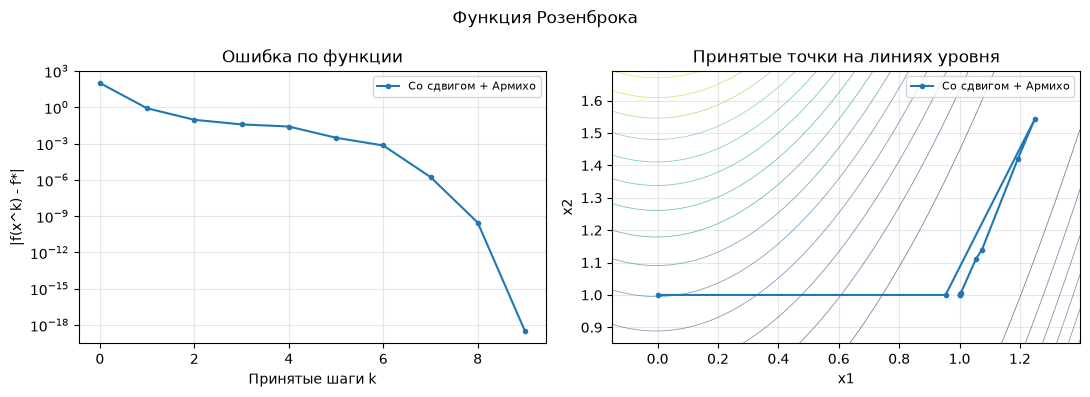

In [ ]:
x0 = np.array([0., 1.])
print('Спектр исходного G:', np.linalg.eigvalsh(rosen_hess(x0)))
unsafe_model = newton(rosenbrock, rosen_grad, rosen_hess, x0, mode='armijo')
print('Без сдвига:', unsafe_model['status'], unsafe_model['message'])
safe = newton(rosenbrock, rosen_grad, rosen_hess, x0, mode='shifted', maxiter=200)
report({'Ньютон со сдвигом': safe})
plot_results(rosenbrock, {'Со сдвигом + Армихо': safe}, 'Функция Розенброка')


## 4. Уравнение секущей и BFGS
Берём $x^0=(0,0)$, $H_0=I$, $\alpha_0=0.1$ для Розенброка.
Проверяем условия $s^Ty>0$, $H_1y=s$ и симметрию новой матрицы.
В последующих итерациях используем линейный поиск и защиту условия кривизны.


In [ ]:
x0 = np.zeros(2)
g0 = rosen_grad(x0)
p0 = -g0
x1 = x0 + 0.1*p0
s, y = x1-x0, rosen_grad(x1)-g0
H1, accepted = bfgs_update(np.eye(2), s, y)
print('s =', s, 'y =', y, 'sᵀy =', s@y)
print('H1 =\n', H1)
print('H1 y - s =', H1@y-s, 'спектр H1 =', np.linalg.eigvalsh(H1))
assert accepted and np.allclose(H1@y, s)
assert np.allclose(H1, [[809/162,20/9],[20/9,1]])


s = [0.2 0. ] y = [ 3.6 -8. ] sᵀy = 0.7200000000000002
H1 =
 [[4.99382716 2.22222222]
 [2.22222222 1.        ]]
H1 y - s = [-7.21644966e-16  0.00000000e+00] спектр H1 = [0.00928317 5.98454399]


## 5. Ограниченная память и библиотечные методы
В L-BFGS хранятся последние $m$ пар $(s_i,y_i)$.
`Newton-CG` &mdash; отдельный алгоритм (берём из библиотеки) с итерационным решением подзадачи и поиском шага Ньютона.


Newton-CG success = True message = Optimization terminated successfully. nit = 83 ||g|| = 1.556066496097877e-05 сек. = 0.00378745899979549
L-BFGS-B success = True message = CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH nit = 36 ||g|| = 6.012388832487832e-05 сек. = 0.0004292920002626488


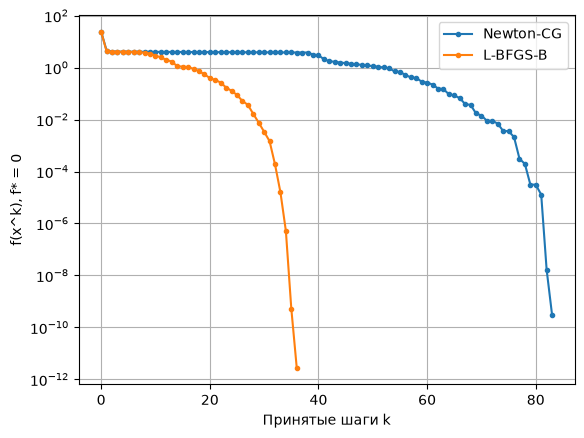

In [ ]:
from scipy.optimize import minimize
x0 = np.array([-1.2, 1.0])
for method in ('Newton-CG', 'L-BFGS-B'):
    path = [x0.copy()]
    options = {'maxiter': 400}
    kwargs = {'hess': rosen_hess} if method == 'Newton-CG' else {}
    t0 = time.perf_counter()
    res = minimize(rosenbrock, x0.copy(), jac=rosen_grad, method=method,
                   callback=lambda xk: path.append(xk.copy()), options=options, **kwargs)
    elapsed = time.perf_counter()-t0
    print(method, 'success =',res.success, 'message =',res.message,
          'nit =',res.nit, '||g|| =',np.linalg.norm(rosen_grad(res.x)), 'сек. =',elapsed)
    values = np.array([rosenbrock(x) for x in path])
    plt.semilogy(np.arange(len(values)), np.maximum(values, np.finfo(float).tiny), '.-', label=method)
plt.xlabel('Принятые шаги k'); plt.ylabel('f(x^k), f* = 0'); plt.grid(); plt.legend(); plt.show()


## Дополнительно: логистическая регрессия

Таргеты $y_i\in\{0,1\}$, оптимизируем лосс: $$f(w)=\frac1N\sum_i[\log(1+e^{x_i^Tw})-y_i x_i^Tw]+\lambda\|w\|^2.$$
Для численной устойчивости используем `logaddexp`, производные считаем аналитически.
Все методы начинают с одной точки и сравниваются по одной норме градиента.
Ниже градиентный метод обрабатывает **всю выборку**, это не SGD.


Метод                      шаги         f(x)        ||g||      сек.  статус; вызовы f/g/G
Полный градиент + Армихо    184   3.1332e-01    9.761e-07    0.0082  converged; {'f': 553, 'grad': 185, 'hess': 0}
Ньютон + Армихо               5   3.1332e-01    1.318e-09    0.0005  converged; {'f': 16, 'grad': 6, 'hess': 5}
BFGS + Вульф                 23   3.1332e-01    8.963e-07    0.0016  converged; {'f': 47, 'grad': 47, 'hess': 0}


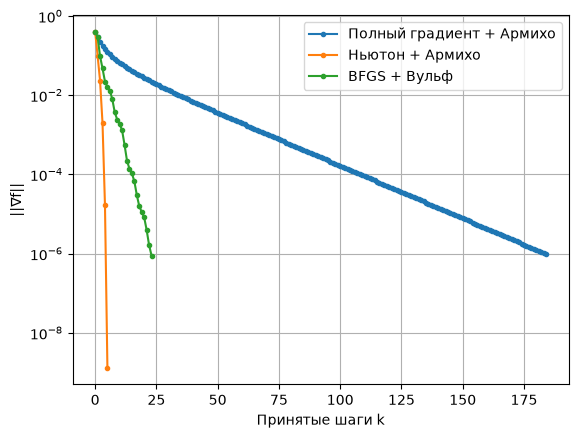

In [ ]:
from scipy.special import expit
rng = np.random.default_rng(9)
X = rng.normal(size=(400,12))
X = (X-X.mean(axis=0))/X.std(axis=0)
w_true = rng.normal(size=12)
y = (rng.random(len(X)) < expit(X@w_true)).astype(float)
l2_reg = 0.01

def logistic_loss(w):
    z = X@w
    return float(np.mean(np.logaddexp(0., z)-y*z)+l2_reg*(w@w))

def logistic_grad(w):
    return X.T@(expit(X@w)-y)/len(y)+2*l2_reg*w

def logistic_hess(w):
    prob = expit(X@w)
    return X.T@((prob*(1-prob))[:,None]*X)/len(y)+2*l2_reg*np.eye(X.shape[1])

w0 = np.zeros(X.shape[1])
results_log = {
    'Полный градиент + Армихо': gradient_descent(logistic_loss,logistic_grad,w0,gtol=1e-6,maxiter=2000),
    'Ньютон + Армихо': newton(logistic_loss,logistic_grad,logistic_hess,w0,mode='armijo',gtol=1e-6),
    'BFGS + Вульф': bfgs(logistic_loss,logistic_grad,w0,gtol=1e-6),
}
report(results_log)
for name,r in results_log.items():
    plt.semilogy(r['grad_history'],'.-',label=name)
plt.xlabel('Принятые шаги k'); plt.ylabel('||∇f||'); plt.legend(); plt.grid(); plt.show()
assert all(r['status']=='converged' for r in results_log.values())


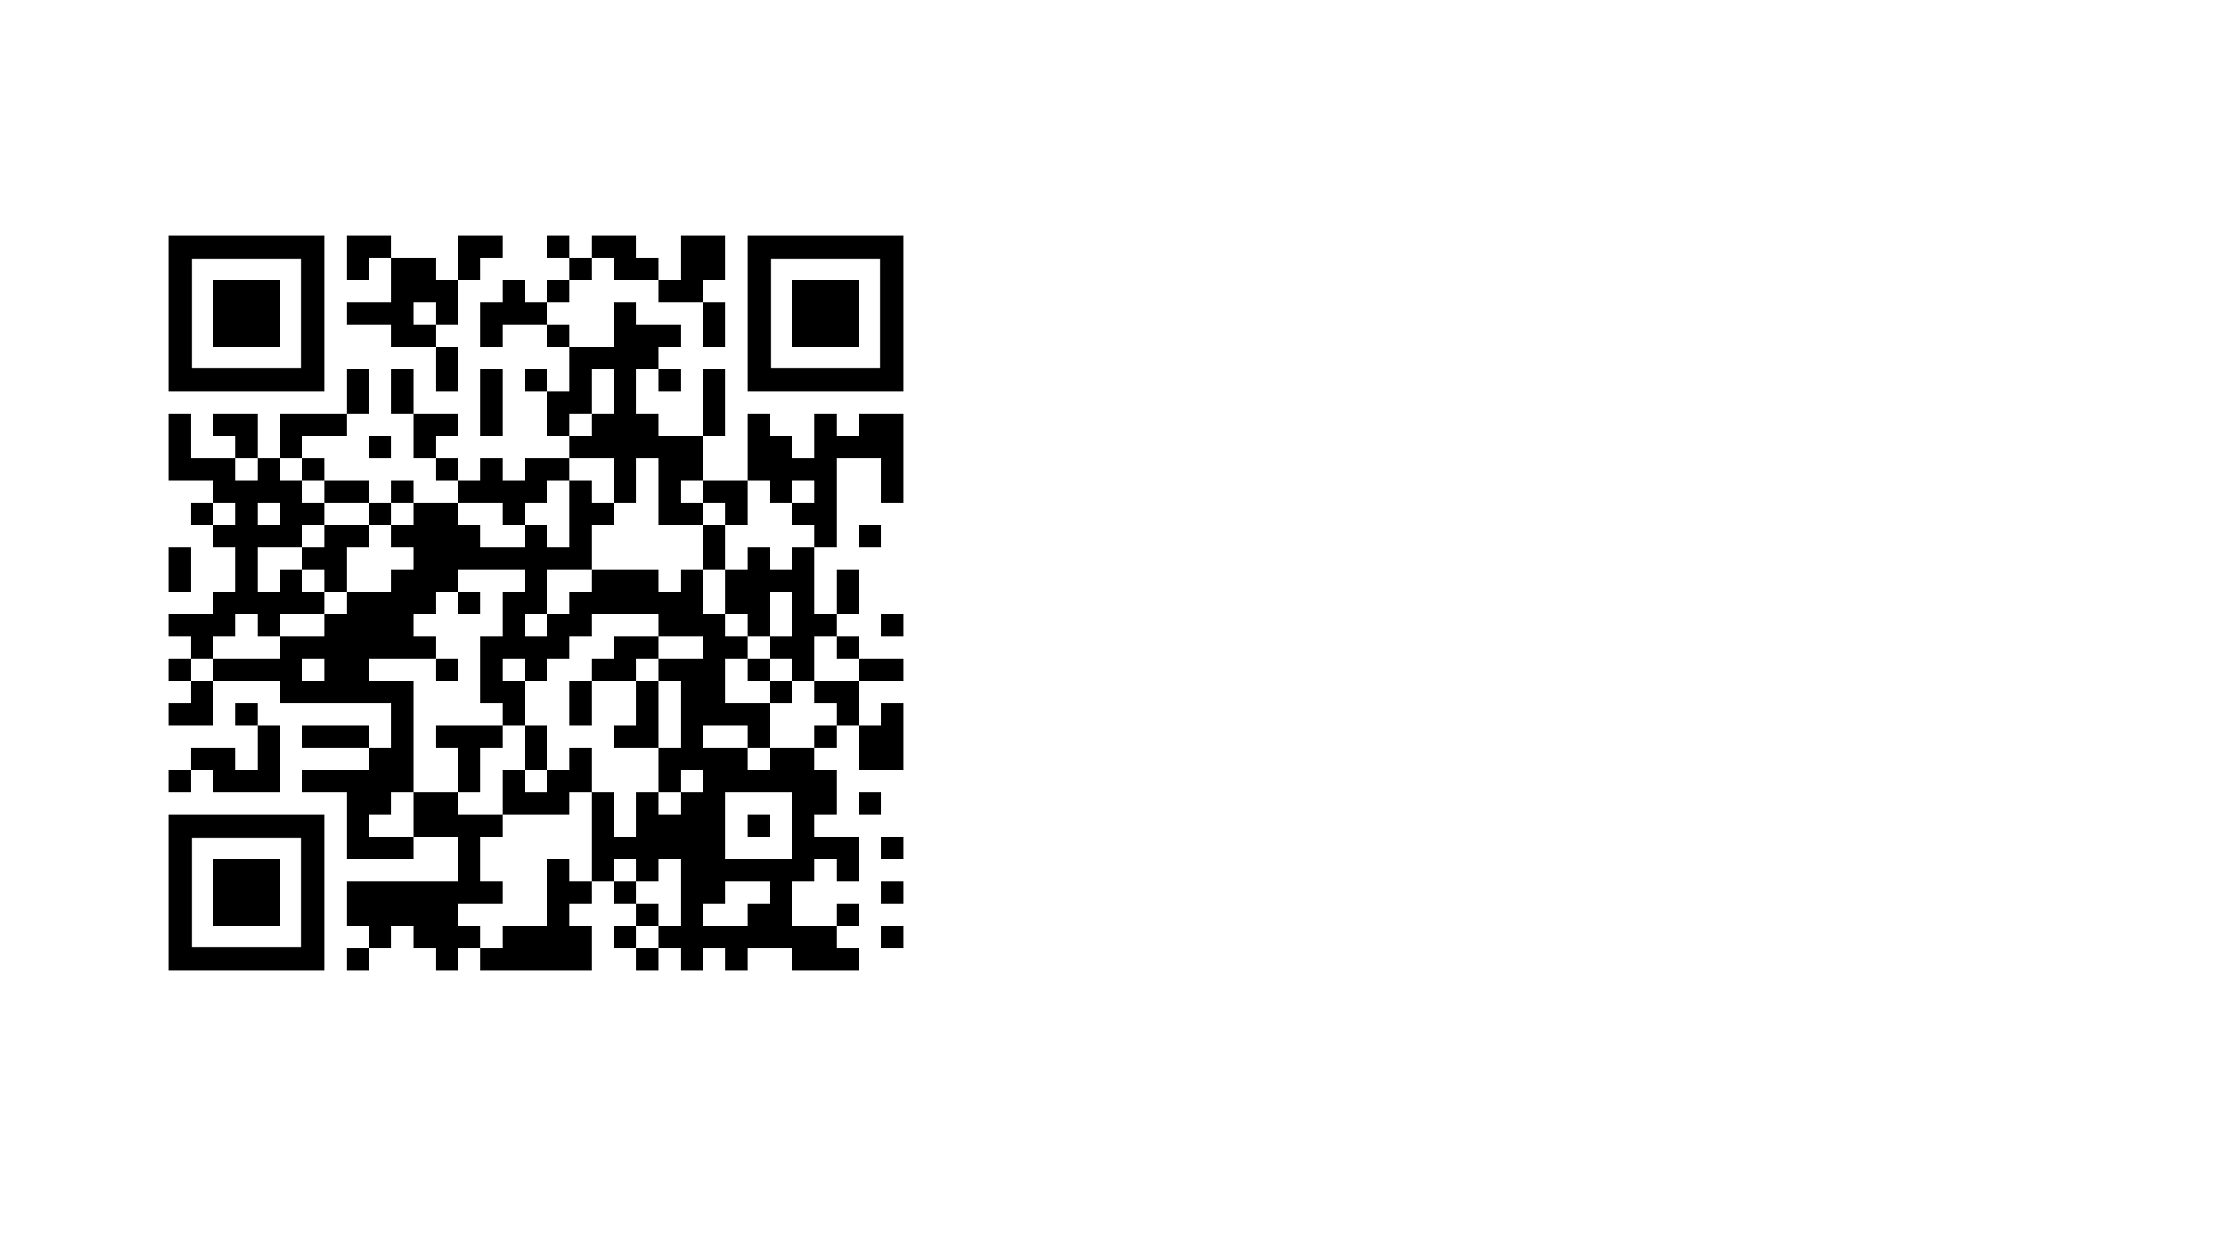